# Bagian Model — MovieMatch (Sistem Rekomendasi Film)
Kelompok 2 Kelas E · Content-Based Filtering (TF-IDF + Cosine Similarity)

Notebook ini mendokumentasikan tahap model: **tags → TF-IDF → cosine similarity → ranking dengan rating → personalisasi & cold start → evaluasi Precision@K / Recall@K**.
Kodenya ada di `src/` (dipakai langsung oleh backend); notebook ini hanya memanggil dan menjelaskannya.

> **PENTING:** jika `data/movies_clean_final.csv` belum ada di folder `data/`, notebook memakai `data/movies_standin.csv`
> (4.803 film dari dataset TMDB 5000 publik, dikonversi ke 9 kolom yang sama) hanya untuk uji kode.
> **Semua angka di notebook ini harus dijalankan ulang pada CSV asli sebelum masuk laporan.**

In [1]:
import sys, time, os
sys.path.insert(0, os.path.abspath('..'))   # akar repo; di Colab: sesuaikan / upload folder src/
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from src.build_model import build_bundle, DEFAULT_CONFIG
from src.recommender import Recommender
from src.evaluation import (evaluate_similar, evaluate_personal, evaluate_manual, evaluate_all,
                            sample_queries, random_baseline, popular_baseline)

CSV = '../data/movies_clean_final.csv'
USING_STANDIN = not os.path.exists(CSV)
if USING_STANDIN:
    CSV = '../data/movies_standin.csv'
    print('PERINGATAN: memakai data STAND-IN, bukan movies_clean_final.csv')
df = pd.read_csv(CSV)
print(df.shape); df.head(3)

(45430, 9)


,id,title,overview,genres_list,keywords_list,director,release_year,vote_average,vote_count
0,2,Ariel,Taisto Kasurinen is a Finnish coal miner whose...,Drama|Crime,underdog|prison|factory worker|prisoner|helsin...,Aki Kaurismäki,1988.0,7.1,44.0
1,3,Shadows in Paradise,"An episode in the life of Nikander, a garbage ...",Drama|Comedy,salesclerk|helsinki|garbage|independent film,Aki Kaurismäki,1986.0,7.1,35.0
2,5,Four Rooms,It's Ted the Bellhop's first night on the job....,Crime|Comedy,hotel|new year's eve|witch|bet|hotel room|sper...,Allison Anders|Alexandre Rockwell|Robert Rodri...,1995.0,6.5,539.0


## 1. Data
Kolom: `id, title, overview, genres_list, keywords_list, director, release_year, vote_average, vote_count` (list dipisah `|`).
Catatan dari PRD isu #8: hitung overview kosong dari CSV, bukan dari `isna()` setelah `fillna('')`.

In [2]:
print('overview kosong :', (df['overview'].fillna('').str.strip() == '').sum())
print('tanpa genre     :', (df['genres_list'].fillna('') == '').sum())
print('tanpa sutradara :', (df['director'].fillna('') == '').sum())
print('id duplikat     :', df['id'].duplicated().sum())
df[['vote_average','vote_count']].describe().round(2)

overview kosong : 959
tanpa genre     : 2442
tanpa sutradara : 888
id duplikat     : 0


,vote_average,vote_count
count,45430.00,45430.00
mean,5.62,109.94
std,1.92,491.47
min,0.00,0.00
25%,5.00,3.00
50%,6.00,10.00
75%,6.80,34.00
max,10.00,14075.00


## 2. Pembentukan `tags` dan TF-IDF
`tags` = overview + genre + keyword + sutradara → case folding, hapus tanda baca, hapus stopword Inggris (di `TfidfVectorizer`).
Genre dan sutradara dijadikan **satu token** (`sciencefiction`, `christophernolan`) supaya tidak bercampur dengan kata di sinopsis.
Matriks TF-IDF disimpan sparse dan L2-normalized, sehingga cosine similarity = perkalian titik, **dihitung per film saat diminta** (matriks penuh ≈ 16,5 GB untuk 45.430 film).

In [3]:
t = time.time(); bundle = build_bundle(df); print(f'build: {time.time()-t:.1f} dtk | matriks {bundle["matrix"].shape} | nnz {bundle["matrix"].nnz:,}')
model = Recommender(bundle)
from src.preprocessing import build_tags, split_list
r = df.iloc[0]; print(r['title']); print(build_tags(r['overview'], split_list(r['genres_list']), split_list(r['keywords_list']), r['director'])[:300])

build: 4.9 dtk | matriks (45430, 47887) | nnz 1,467,930
Ariel
taisto kasurinen is a finnish coal miner whose father has just committed suicide and who is framed for a crime he did not commit in jail he starts to dream about leaving the country and starting a new life he escapes from prison but things dont go as planned drama crime underdog prison factory worke


## 3. Contoh hasil `recommend()` + kecepatan (NF-01)

In [4]:
pick = model.movies.sort_values('vote_count', ascending=False).iloc[0]
print('Acuan:', pick['title'])
t = time.time(); res = model.recommend(int(pick['id']), 10); ms = (time.time()-t)*1000
print(f'{ms:.1f} ms\n')
pd.DataFrame(res)[['title','release_year','similarity','score','vote_average','reasons']]

Acuan: Inception
11.0 ms



,title,release_year,similarity,score,vote_average,reasons
0,The Flying Man,2013,0.1673,0.8711,4.2,"[Genre: Action, Mystery, Science Fiction]"
1,Cypher,2002,0.1210,0.6874,6.7,"[Genre: Thriller, Science Fiction, Mystery]"
2,UFO - Distruggete base Luna!,1971,0.1258,0.6782,0.0,"[Genre: Science Fiction, Action, Thriller]"
3,Altitude,2017,0.1246,0.6354,4.1,"[Genre: Action, Thriller]"
4,Bottom of the World,2017,0.1180,0.6317,5.5,"[Genre: Mystery, Thriller, Kata kunci: subcons..."
5,III,2015,0.1145,0.6210,5.7,[Genre: Thriller]
6,Straight Story,2006,0.1098,0.5970,5.2,"[Genre: Science Fiction, Kata kunci: dream]"
7,Force,2011,0.1074,0.5922,6.2,"[Genre: Action, Thriller]"
8,Following,1998,0.0946,0.5908,7.2,"[Sutradara sama: Christopher Nolan, Genre: Thr..."
9,Abduction,2011,0.1106,0.5825,5.6,"[Genre: Thriller, Action, Mystery, Kata kunci:..."


## 4. Eksperimen: konfigurasi TF-IDF dan bobot `tags`
Metrik: Precision@10 pada 300 film acuan acak (definisi relevan: Jaccard genre ≥ 0,5, lihat §6).

**Awas sirkular:** genre ikut dipakai di `tags` *dan* di definisi relevan, jadi menaikkan `genre_weight` otomatis menaikkan skor tanpa berarti rekomendasinya lebih baik.
Karena itu `genre_weight` **tidak dipilih berdasarkan skor ini**; default tetap 1 (semua bagian setara).

In [5]:
q = sample_queries(model, 300, seed=42)
rows = []
for name, cfg in {
    'default': {}, 'genre x2': dict(genre_weight=2), 'genre x3': dict(genre_weight=3),
    'keyword x2': dict(keyword_weight=2), 'director x2': dict(director_weight=2),
    'bigram (1,2)': dict(ngram_range=(1,2)), 'min_df=1': dict(min_df=1), 'max_df=0.5': dict(max_df=0.5),
}.items():
    m = Recommender(build_bundle(df, **cfg))
    rows.append({'konfigurasi': name, 'P@10 serupa': evaluate_similar(m, q)['P@10'], 'P@10 personal': evaluate_personal(m)['P@10']})
pd.DataFrame(rows).round(3)

,konfigurasi,P@10 serupa,P@10 personal
0,default,0.394,0.236
1,genre x2,0.566,0.286
2,genre x3,0.677,0.308
3,keyword x2,0.381,0.216
4,director x2,0.400,0.246
5,"bigram (1,2)",0.449,0.242
6,min_df=1,0.390,0.239
7,max_df=0.5,0.394,0.236


## 5. Bobot rating pada ranking (isu #4 PRD)
`score = (1 − α)·similarity_ternormalisasi + α·rating_ternormalisasi`, dengan rating = *weighted rating* gaya IMDb (film dengan sedikit vote ditarik ke rata-rata).
`similarity` yang ditampilkan ke pengguna tetap cosine mentah; `score` hanya untuk urutan.

In [6]:
alphas = [0, 0.1, 0.2, 0.3, 0.5, 0.7]
sw = pd.DataFrame([{'alpha': a, 'P@10': evaluate_similar(model, q, alpha=a)['P@10'],
                    'rating rata-rata Top-10': np.mean([x['vote_average'] for qq in q[:100] for x in model.recommend(qq, 10, alpha=a)])}
                   for a in alphas]).round(3)
sw

,alpha,P@10,rating rata-rata Top-10
0,0.0,0.395,5.628
1,0.1,0.396,5.753
2,0.2,0.394,5.964
3,0.3,0.390,6.264
4,0.5,0.376,7.064
5,0.7,0.351,7.464


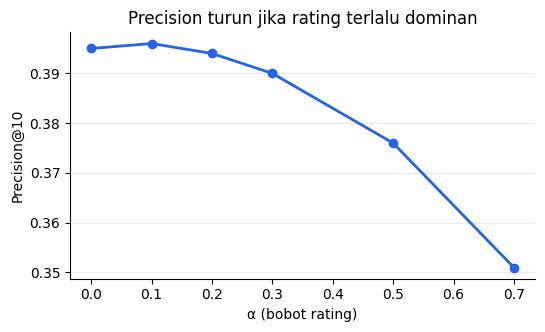

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sw['alpha'], sw['P@10'], marker='o', color='#2563eb', lw=2)
ax.set_xlabel('α (bobot rating)'); ax.set_ylabel('Precision@10'); ax.set_title('Precision turun jika rating terlalu dominan')
ax.spines[['top','right']].set_visible(False); ax.grid(axis='y', alpha=.25); plt.show()

**Pilihan default α = 0,2** [Usulan]: Precision tidak turun dibanding α = 0, tetapi film berating tinggi naik di urutan. Di atas ≈ 0,3 Precision mulai turun.
Tim boleh mengubahnya lewat `DEFAULT_CONFIG["alpha"]` atau argumen `--alpha` di `build_model`.

### Menggabungkan riwayat: `max` vs `mean`
`max` (default) = kandidat dari tiap film riwayat digabung, nilai terbaik yang dipakai (sesuai PRD, cocok untuk selera beragam).
`mean` = film yang mirip dengan *banyak* film riwayat naik. Pengguna simulasi di bawah punya selera satu genre, jadi mengunggulkan `mean`; hasilnya belum tentu berlaku untuk pengguna asli.

In [8]:
pd.DataFrame({agg: evaluate_personal(model, agg=agg) for agg in ['max','mean']}).T[['P@5','R@5','P@10','R@10']].round(3)

,P@5,R@5,P@10,R@10
max,0.266,0.002,0.236,0.004
mean,0.322,0.002,0.291,0.004


## 6. Evaluasi Precision@K dan Recall@K (K = 5 dan 10)
**Definisi relevan [Usulan, perlu disepakati tim]:** film *j* relevan terhadap acuan *q* jika Jaccard genre(*j*, *q*) ≥ 0,5.
Tiga fungsi diuji sesuai PRD §14: film serupa, rekomendasi personal (pengguna simulasi: 3 film riwayat satu selera, relevan = film berating ≥ 6,5 dengan selera yang sama yang belum ada di riwayat), dan cari film serupa manual (acuan dari 200 film populer, 12 hasil).

Recall@K otomatis kecil karena himpunan relevan berisi ratusan film (kolom `avg_relevant`); bandingkan dengan baseline, bukan dengan 1,0.

In [9]:
final = evaluate_all(model); final.round(4)

,P@5,R@5,P@10,R@10,avg_relevant,n_queries
Film serupa (recommend),0.4267,0.0008,0.394,0.0015,5013.2967,300.0
Rekomendasi personal (recommend_for_user),0.2660,0.0024,0.236,0.0036,1664.4700,100.0
"Cari film serupa manual (recommend, n=12)",0.4960,0.0011,0.458,0.0020,5088.7100,100.0


,P@5,R@5,P@10,R@10
Model (recommend),0.4267,0.0008,0.394,0.0015
Baseline populer,0.1473,0.0001,0.138,0.0003
Baseline acak,0.1100,0.0001,0.103,0.0002


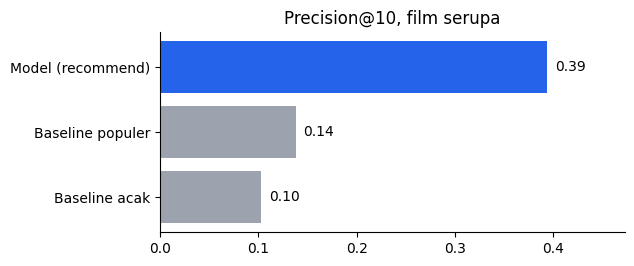

In [10]:
q = sample_queries(model, 300, seed=42)
base = pd.DataFrame({
    'Model (recommend)': evaluate_similar(model, q),
    'Baseline populer':  evaluate_similar(model, q, recommend_fn=popular_baseline(model)),
    'Baseline acak':     evaluate_similar(model, q, recommend_fn=random_baseline(model)),
}).T[['P@5','R@5','P@10','R@10']]
display(base.round(4))
fig, ax = plt.subplots(figsize=(6, 2.6))
vals = base['P@10']; colors = ['#2563eb', '#9ca3af', '#9ca3af']
bars = ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1])
for b, v in zip(bars, vals.values[::-1]): ax.text(v + .008, b.get_y()+b.get_height()/2, f'{v:.2f}', va='center')
ax.set_xlim(0, max(vals)*1.2); ax.set_title('Precision@10, film serupa'); ax.spines[['top','right']].set_visible(False); plt.show()

## 7. Distribusi `similarity` (untuk ambang warna badge, isu #14)
Desain memakai ≥ 80 kuning, ≥ 60 hijau, selain itu abu. Cosine TF-IDF asli jauh lebih rendah, jadi ambang perlu disesuaikan dengan sebaran di bawah.

,P10,P25,median,P75,P90,P99
% Mirip (Top-10),11.6,13.4,16.1,19.7,23.8,40.4


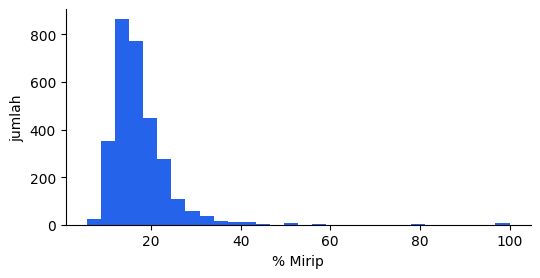

In [11]:
sims = np.array([x['similarity'] for qq in q for x in model.recommend(qq, 10)])
pct = pd.Series(np.percentile(sims*100, [10, 25, 50, 75, 90, 99]).round(1), index=['P10','P25','median','P75','P90','P99'], name='% Mirip (Top-10)')
display(pct.to_frame().T)
fig, ax = plt.subplots(figsize=(6, 2.8)); ax.hist(sims*100, bins=30, color='#2563eb'); ax.set_xlabel('% Mirip'); ax.set_ylabel('jumlah'); ax.spines[['top','right']].set_visible(False); plt.show()

**Usulan ambang** (menyesuaikan sebaran di atas): kuning = di atas P90, hijau = di atas median, sisanya abu. Angkanya harus dihitung ulang pada CSV asli.

## 8. Personalisasi dan cold start

In [12]:
hist = [int(x) for x in model.movies.sort_values('vote_count', ascending=False)['id'].iloc[[0, 5, 10]]]
print('Riwayat (terbaru dulu):', [model.movies.set_index('id').loc[h, 'title'] for h in hist])
pd.DataFrame(model.recommend_for_user(hist, 8))[['title','similarity','score','source_movie_id','reasons']]

Riwayat (terbaru dulu): ['Inception', 'Interstellar', 'Mad Max: Fury Road']


,title,similarity,score,source_movie_id,reasons
0,The Desert,0.2219,0.9131,76341,"[Genre: Science Fiction, Kata kunci: post-apoc..."
1,Planet of the Apes,0.1946,0.8809,157336,"[Genre: Science Fiction, Adventure, Drama, Kat..."
2,The Day,0.2200,0.8720,76341,"[Genre: Action, Science Fiction, Kata kunci: p..."
3,Mad Max,0.1998,0.8605,76341,"[Sutradara sama: George Miller, Genre: Adventu..."
4,Mission to Mir,0.2048,0.8473,157336,"[Kata kunci: nasa, space travel, astronaut]"
5,Mad Max 2: The Road Warrior,0.1834,0.8318,76341,"[Sutradara sama: George Miller, Genre: Adventu..."
6,Steel Dawn,0.1955,0.7963,76341,"[Genre: Action, Adventure, Science Fiction, Ka..."
7,Turbo Kid,0.1791,0.7893,76341,"[Genre: Action, Adventure, Science Fiction, Ka..."


In [13]:
print('Riwayat kosong -> popular():')
pd.DataFrame(model.recommend_for_user([], 8))[['title','vote_average','vote_count','score']]

Riwayat kosong -> popular():


,title,vote_average,vote_count,score
0,Dilwale Dulhania Le Jayenge,9.1,661,0.8858
1,The Shawshank Redemption,8.5,8358,0.8483
2,The Godfather,8.5,6024,0.8477
3,Your Name.,8.5,1030,0.8371
4,The Dark Knight,8.3,12269,0.8290
5,Fight Club,8.3,9678,0.8287
6,Pulp Fiction,8.3,8670,0.8285
7,Schindler's List,8.3,4436,0.8271


## 9. Menyimpan artefak untuk backend
```
python -m src.build_model --csv data/movies_clean_final.csv --out models/recommender.joblib
```
Backend memakai `from src.recommender import recommend, recommend_for_user, popular` (lihat `docs/model-README.md`).